# Customer Behaviour & Dimensionality Reduction

Проект посвящён анализу поведения клиентов интернет-магазина
и снижению размерности данных с помощью PCA и t-SNE.

Цель — выделить наиболее информативные признаки, сократить размерность
без существенной потери информации и исследовать структуру клиентских данных.

## 1. Данные и первичный анализ

В работе используется датасет с данными о 1000 клиентах интернет-магазина.

В набор входят:
- демографические характеристики;
- параметры подписки;
- активность на сайте;
- история покупок;
- используемая платформа;
- факт покупки в прошлом месяце.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Customer Behavior Dataset.csv')

df.head()

,CustomerID,Age,Gender,Membership,Annual_Income_kUSD,Region,Platform,Product_Preference,Visits_per_Month,Time_Spent_per_Visit_min,Pages_Visited_per_Session,Previous_Purchases,Avg_Purchase_Value_USD,Total_Purchase_Value_USD,Days_Since_Last_Purchase,Made_Purchase_Last_Month,Will_Purchase_Next_Month,Next_Month_Spend_USD
0,1,40,Male,NaN,40.58,Central,Mobile,Apparel,5,6.0,5,1,NaN,42.43,0,0,0,0.0
1,2,33,Male,NaN,53.20,West,Mobile,Apparel,3,9.0,2,0,25.95,0.00,206,0,0,0.0
2,3,42,Female,NaN,73.70,West,Mobile,Home & Kitchen,3,13.9,2,0,71.06,13.92,15,0,0,0.0
3,4,51,Female,NaN,45.95,East,Mobile,Sports,3,1.0,4,1,35.81,91.43,149,0,0,0.0
4,5,32,Male,Premium,45.32,East,Mobile,Apparel,11,11.1,7,3,5.00,37.75,6,1,0,0.0


In [ ]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum())

Размер датасета: (1000, 18)

Типы данных:
CustomerID                     int64
Age                            int64
Gender                        object
Membership                    object
Annual_Income_kUSD           float64
Region                        object
Platform                      object
Product_Preference            object
Visits_per_Month               int64
Time_Spent_per_Visit_min     float64
Pages_Visited_per_Session      int64
Previous_Purchases             int64
Avg_Purchase_Value_USD       float64
Total_Purchase_Value_USD     float64
Days_Since_Last_Purchase       int64
Made_Purchase_Last_Month       int64
Will_Purchase_Next_Month       int64
Next_Month_Spend_USD         float64
dtype: object

Количество пропусков:
CustomerID                     0
Age                            0
Gender                        30
Membership                   467
Annual_Income_kUSD             0
Region                         0
Platform                       0
Product_Preference      

In [ ]:
# Целевая переменная отдельно
target = df['Made_Purchase_Last_Month'].copy()

# Признаки для дальнейшего анализа
X = df.drop(columns=[
    'CustomerID',
    'Made_Purchase_Last_Month',
    'Will_Purchase_Next_Month',
    'Next_Month_Spend_USD'
]).copy()

print('Размер таблицы признаков:', X.shape)
print('\nПропуски до обработки:')
print(X.isnull().sum()[X.isnull().sum() > 0])

Размер таблицы признаков: (1000, 14)

Пропуски до обработки:
Gender                       30
Membership                  467
Time_Spent_per_Visit_min     60
Avg_Purchase_Value_USD       40
dtype: int64


## 2. Подготовка данных

Перед применением методов снижения размерности обрабатываю пропуски,
кодирую категориальные признаки и стандартизирую числовые переменные.

Стандартизация необходима, поскольку PCA и t-SNE чувствительны
к различиям в масштабе признаков.

In [ ]:
# У категориальных признаков задаем клиенту значение "Unknown"
X['Gender'] = X['Gender'].fillna('Unknown')
X['Membership'] = X['Membership'].fillna('Unknown')

# Распределение времени почти симметричное, поэтому используем среднее
time_mean = X['Time_Spent_per_Visit_min'].mean()
X['Time_Spent_per_Visit_min'] = (
    X['Time_Spent_per_Visit_min'].fillna(time_mean)
)

# Средний чек имеет правостороннюю асимметрию, поэтому используем медиану
purchase_median = X['Avg_Purchase_Value_USD'].median()
X['Avg_Purchase_Value_USD'] = (
    X['Avg_Purchase_Value_USD'].fillna(purchase_median)
)

print('Пропусков после обработки:', X.isnull().sum().sum())
print('Среднее время:', round(time_mean, 2))
print('Медианный средний чек:', round(purchase_median, 2))

Пропусков после обработки: 0
Среднее время: 8.96
Медианный средний чек: 35.67


In [ ]:
# Категориальные признаки
categorical_columns = [
    'Gender',
    'Membership',
    'Region',
    'Platform',
    'Product_Preference'
]

# Запоминаем базовые категории, которые будут исключены
reference_levels = {
    column: sorted(X[column].unique())[0]
    for column in categorical_columns
}

# One-Hot Encoding
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print('До кодирования:', X.shape)
print('После кодирования:', X_encoded.shape)
print('Осталось пропусков:', X_encoded.isna().sum().sum())
print(
    'Нечисловые столбцы:',
    X_encoded.select_dtypes(exclude='number').columns.tolist()
)

print('\nБазовые категории:')
for column, level in reference_levels.items():
    print(f'{column}: {level}')

До кодирования: (1000, 14)
После кодирования: (1000, 24)
Осталось пропусков: 0
Нечисловые столбцы: []

Базовые категории:
Gender: Female
Membership: Basic
Region: Central
Platform: Desktop
Product_Preference: Apparel


Категориальные признаки преобразованы с помощью One-Hot Encoding.

Для переменных с пропусками используется отдельная категория `Unknown`,
чтобы не приписывать объектам отсутствующее значение.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_encoded),
    columns=X_encoded.columns,
    index=X_encoded.index
)

print('Размер данных:', X_scaled.shape)
print('Количество пропусков:', X_scaled.isna().sum().sum())

print(
    'Максимальное отклонение среднего от 0:',
    X_scaled.mean().abs().max()
)

print(
    'Максимальное отклонение стандартного отклонения от 1:',
    (X_scaled.std(ddof=0) - 1).abs().max()
)

X_scaled.head()

Размер данных: (1000, 24)
Количество пропусков: 0
Максимальное отклонение среднего от 0: 1.4210854715202004e-16
Максимальное отклонение стандартного отклонения от 1: 9.992007221626409e-15


,Age,Annual_Income_kUSD,Visits_per_Month,Time_Spent_per_Visit_min,Pages_Visited_per_Session,Previous_Purchases,Avg_Purchase_Value_USD,Total_Purchase_Value_USD,Days_Since_Last_Purchase,Gender_Male,...,Region_North,Region_South,Region_West,Platform_Mobile,Platform_Tablet,Product_Preference_Beauty,Product_Preference_Books,Product_Preference_Electronics,Product_Preference_Home & Kitchen,Product_Preference_Sports
0,0.490452,-0.846667,0.055363,-0.719274,0.142790,-0.402469,-0.183075,-0.375382,-0.975831,1.112266,...,-0.546536,-0.509358,-0.476439,0.63755,-0.178862,-0.410152,-0.388263,-0.466933,-0.470108,-0.460566
1,-0.189517,-0.255229,-0.713568,0.009799,-1.027618,-0.981562,-0.498984,-0.718052,2.320895,1.112266,...,-0.546536,-0.509358,2.098906,0.63755,-0.178862,-0.410152,-0.388263,-0.466933,-0.470108,-0.460566
2,0.684729,0.705508,-0.713568,1.200617,-1.027618,-0.981562,0.967889,-0.605633,-0.735778,-0.899065,...,-0.546536,-0.509358,2.098906,0.63755,-0.178862,-0.410152,-0.388263,-0.466933,2.127172,-0.460566
3,1.558974,-0.595001,-0.713568,-1.934395,-0.247346,-0.402469,-0.178360,0.020348,1.408694,-0.899065,...,-0.546536,-0.509358,-0.476439,0.63755,-0.178862,-0.410152,-0.388263,-0.466933,-0.470108,2.171241
4,-0.286655,-0.624526,2.362157,0.520149,0.923061,0.755716,-1.180230,-0.413179,-0.879810,1.112266,...,-0.546536,-0.509358,-0.476439,0.63755,-0.178862,-0.410152,-0.388263,-0.466933,-0.470108,-0.460566


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Добавляем целевую переменную только для анализа корреляций
data_for_correlation = X_scaled.copy()
data_for_correlation['Made_Purchase_Last_Month'] = target.values

corr_matrix = data_for_correlation.corr()

# Связь каждого признака с целевой переменной
target_correlation = (
    corr_matrix['Made_Purchase_Last_Month']
    .drop('Made_Purchase_Last_Month')
    .sort_values(key=abs, ascending=False)
)

print('Корреляция признаков с целевой переменной:')
print(target_correlation.round(3))

Корреляция признаков с целевой переменной:
Membership_Premium                   0.301
Visits_per_Month                     0.293
Previous_Purchases                   0.202
Membership_Unknown                  -0.179
Total_Purchase_Value_USD             0.147
Pages_Visited_per_Session            0.141
Annual_Income_kUSD                   0.116
Time_Spent_per_Visit_min             0.088
Age                                 -0.077
Product_Preference_Sports            0.068
Avg_Purchase_Value_USD               0.058
Platform_Mobile                      0.052
Product_Preference_Beauty           -0.037
Gender_Unknown                      -0.034
Product_Preference_Electronics      -0.020
Region_West                          0.020
Gender_Male                          0.020
Region_South                        -0.017
Region_East                         -0.012
Days_Since_Last_Purchase             0.010
Platform_Tablet                      0.010
Region_North                         0.008
Product_Pre

In [ ]:
feature_corr = X_scaled.corr().abs()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_correlation_pairs = (
    upper_triangle.stack()
    .loc[lambda values: values > 0.8]
    .sort_values(ascending=False)
)

if high_correlation_pairs.empty:
    print('Пар признаков с корреляцией выше 0.8 нет.')
else:
    print(high_correlation_pairs)

Пар признаков с корреляцией выше 0.8 нет.


In [ ]:
selected_features = [
    'Membership_Premium',
    'Visits_per_Month',
    'Previous_Purchases',
    'Membership_Unknown',
    'Total_Purchase_Value_USD',
    'Pages_Visited_per_Session',
    'Annual_Income_kUSD',
    'Time_Spent_per_Visit_min',
    'Age',
    'Product_Preference_Sports',
    'Avg_Purchase_Value_USD',
    'Platform_Mobile'
]

X_selected = X_scaled[selected_features]

print('Размер выбранного набора:', X_selected.shape)
print('Выбранные признаки:')

for number, feature in enumerate(selected_features, start=1):
    print(number, feature)

Размер выбранного набора: (1000, 12)
Выбранные признаки:
1 Membership_Premium
2 Visits_per_Month
3 Previous_Purchases
4 Membership_Unknown
5 Total_Purchase_Value_USD
6 Pages_Visited_per_Session
7 Annual_Income_kUSD
8 Time_Spent_per_Visit_min
9 Age
10 Product_Preference_Sports
11 Avg_Purchase_Value_USD
12 Platform_Mobile


## 3. Отбор признаков

Для предварительной оценки связей между признаками строю корреляционную матрицу
и анализирую их связь с фактом покупки.

Корреляция используется как один из критериев отбора, но не как единственный,
поскольку она отражает в основном линейные зависимости.

### Корреляционная матрица

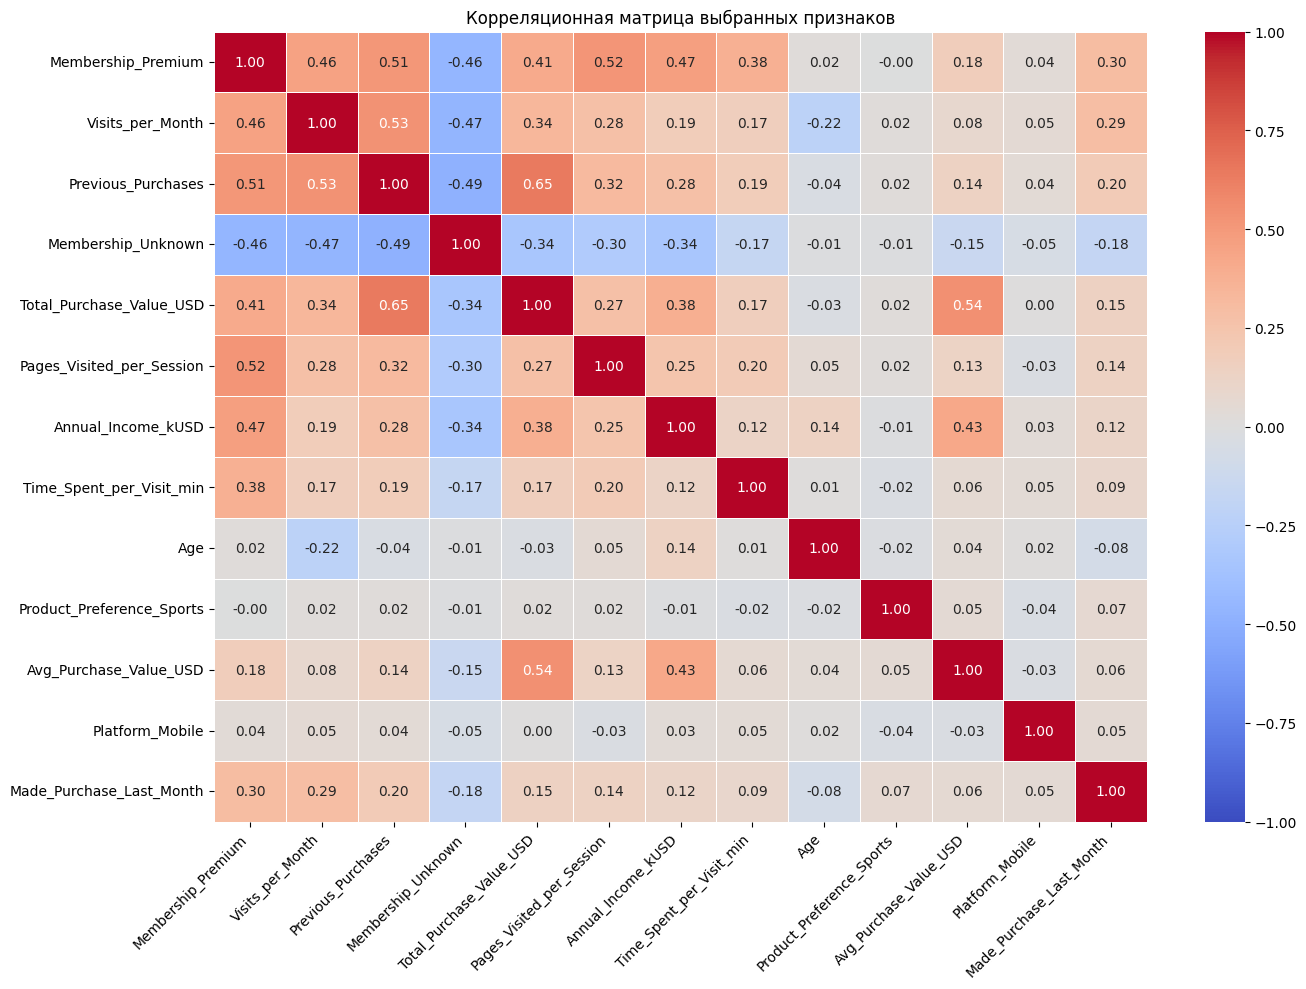

In [ ]:
selected_with_target = X_selected.copy()
selected_with_target['Made_Purchase_Last_Month'] = target.values

plt.figure(figsize=(14, 10))

sns.heatmap(
    selected_with_target.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Корреляционная матрица выбранных признаков')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Вывод по корреляционному анализу

Наиболее заметная положительная связь с фактом покупки наблюдается у:

- `Membership_Premium` — около 0,30;
- `Visits_per_Month` — около 0,29;
- `Previous_Purchases` — около 0,20;
- `Total_Purchase_Value_USD` — около 0,15;
- `Pages_Visited_per_Session` — около 0,14.

Это показывает, что покупка чаще встречается у более активных клиентов,
Premium-пользователей и клиентов с историей предыдущих покупок.

При этом корреляция не означает причинно-следственную связь.

In [ ]:
!pip install factor_analyzer -q

from factor_analyzer.factor_analyzer import (
    calculate_bartlett_sphericity,
    calculate_kmo
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
chi_square_value, p_value = calculate_bartlett_sphericity(X_selected)

kmo_per_feature, kmo_total = calculate_kmo(X_selected)

print('Критерий Бартлетта:')
print('Chi-square:', round(chi_square_value, 3))
print('p-value:', p_value)

print('\nОбщий показатель KMO:', round(kmo_total, 3))

kmo_table = pd.DataFrame({
    'Признак': X_selected.columns,
    'KMO': kmo_per_feature
}).sort_values('KMO')

display(kmo_table)

Критерий Бартлетта:
Chi-square: 3177.166
p-value: 0.0

Общий показатель KMO: 0.739


,Признак,KMO
9,Product_Preference_Sports,0.427424
8,Age,0.427574
10,Avg_Purchase_Value_USD,0.534439
11,Platform_Mobile,0.605622
4,Total_Purchase_Value_USD,0.672803
2,Previous_Purchases,0.711452
7,Time_Spent_per_Visit_min,0.760982
6,Annual_Income_kUSD,0.773191
0,Membership_Premium,0.786881
1,Visits_per_Month,0.807376


### Проверка пригодности данных для PCA

Для оценки пригодности данных к применению PCA используются:

- KMO — показывает, насколько структура корреляций подходит для факторного анализа;
- тест Бартлетта — проверяет, отличаются ли корреляции от случайной структуры.

In [ ]:
features_to_remove = [
    'Product_Preference_Sports',
    'Age'
]

X_final = X_selected.drop(columns=features_to_remove)

print('Исключённые признаки:', features_to_remove)
print('Итоговый размер данных:', X_final.shape)
print('Итоговые признаки:')

for number, feature in enumerate(X_final.columns, start=1):
    print(number, feature)

Исключённые признаки: ['Product_Preference_Sports', 'Age']
Итоговый размер данных: (1000, 10)
Итоговые признаки:
1 Membership_Premium
2 Visits_per_Month
3 Previous_Purchases
4 Membership_Unknown
5 Total_Purchase_Value_USD
6 Pages_Visited_per_Session
7 Annual_Income_kUSD
8 Time_Spent_per_Visit_min
9 Avg_Purchase_Value_USD
10 Platform_Mobile


In [ ]:
chi_square_final, p_value_final = calculate_bartlett_sphericity(X_final)

kmo_per_feature_final, kmo_total_final = calculate_kmo(X_final)

print('Итоговый критерий Бартлетта:')
print('Chi-square:', round(chi_square_final, 3))
print('p-value:', p_value_final)

print('\nИтоговый KMO:', round(kmo_total_final, 3))

final_kmo_table = pd.DataFrame({
    'Признак': X_final.columns,
    'KMO': kmo_per_feature_final
}).sort_values('KMO')

display(final_kmo_table)

Итоговый критерий Бартлетта:
Chi-square: 3066.016
p-value: 0.0

Итоговый KMO: 0.749


,Признак,KMO
8,Avg_Purchase_Value_USD,0.534241
9,Platform_Mobile,0.615285
4,Total_Purchase_Value_USD,0.675385
2,Previous_Purchases,0.713992
7,Time_Spent_per_Visit_min,0.761200
6,Annual_Income_kUSD,0.771347
0,Membership_Premium,0.784344
5,Pages_Visited_per_Session,0.838598
1,Visits_per_Month,0.850510
3,Membership_Unknown,0.883546


### Вывод по отбору признаков

После исключения слабых признаков итоговый набор содержит 10 характеристик.

Общий KMO увеличился примерно до 0,749,
а тест Бартлетта оказался статистически значимым (`p < 0.001`).

Это подтверждает, что выбранный набор признаков подходит для применения PCA.

## 4. PCA

Метод главных компонент используется для уменьшения размерности данных
с сохранением большей части исходной информации.

Сначала анализирую накопленную объяснённую дисперсию,
чтобы определить оптимальное количество компонент.

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Сначала строим PCA со всеми компонентами
pca_full = PCA()
pca_full.fit(X_final)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_results = pd.DataFrame({
    'Компонента': [
        f'PC{i}' for i in range(1, len(explained_variance) + 1)
    ],
    'Доля дисперсии': explained_variance,
    'Накопленная доля': cumulative_variance
})

display(
    pca_results.style.format({
        'Доля дисперсии': '{:.3f}',
        'Накопленная доля': '{:.3f}'
    })
)

,Компонента,Доля дисперсии,Накопленная доля
0,PC1,0.365,0.365
1,PC2,0.129,0.494
2,PC3,0.101,0.595
3,PC4,0.099,0.695
4,PC5,0.081,0.775
5,PC6,0.069,0.844
6,PC7,0.053,0.897
7,PC8,0.051,0.948
8,PC9,0.031,0.979
9,PC10,0.021,1.000


In [ ]:
components_80 = np.argmax(cumulative_variance >= 0.80) + 1
components_85 = np.argmax(cumulative_variance >= 0.85) + 1
components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print('Для сохранения не менее 80%:', components_80)
print('Для сохранения не менее 85%:', components_85)
print('Для сохранения не менее 90%:', components_90)

Для сохранения не менее 80%: 6
Для сохранения не менее 85%: 7
Для сохранения не менее 90%: 8


### Scree plot

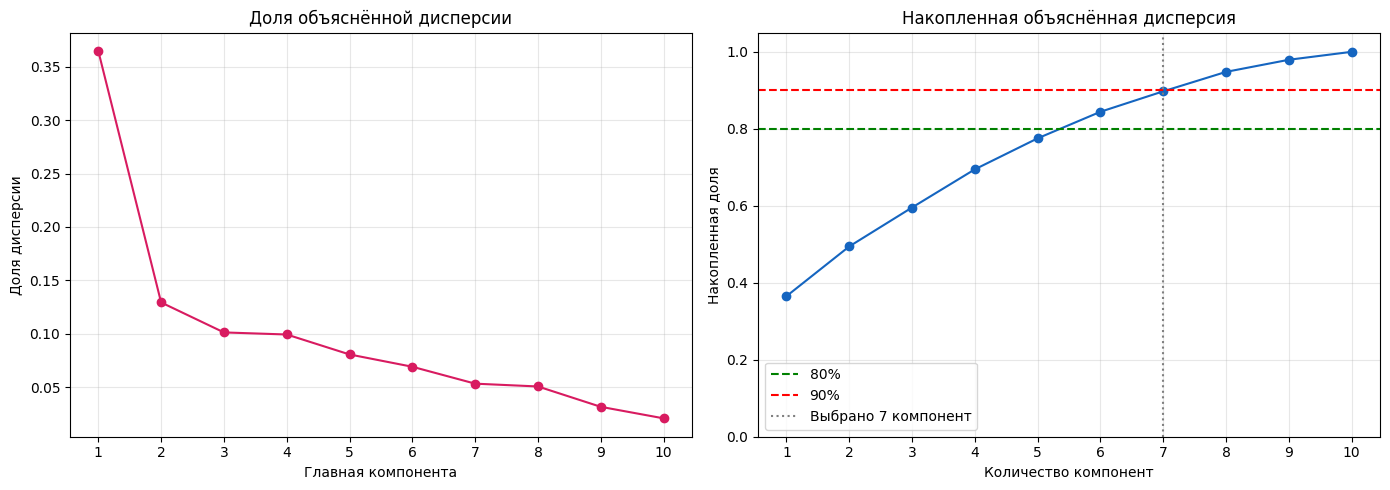

In [ ]:
component_numbers = np.arange(
    1,
    len(explained_variance) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Доля дисперсии каждой компоненты
axes[0].plot(
    component_numbers,
    explained_variance,
    marker='o',
    color='#D81B60'
)

axes[0].set_title('Доля объяснённой дисперсии')
axes[0].set_xlabel('Главная компонента')
axes[0].set_ylabel('Доля дисперсии')
axes[0].set_xticks(component_numbers)
axes[0].grid(alpha=0.3)

# Накопленная дисперсия
axes[1].plot(
    component_numbers,
    cumulative_variance,
    marker='o',
    color='#1565C0'
)

axes[1].axhline(
    0.80,
    color='green',
    linestyle='--',
    label='80%'
)

axes[1].axhline(
    0.90,
    color='red',
    linestyle='--',
    label='90%'
)

axes[1].axvline(
    7,
    color='gray',
    linestyle=':',
    label='Выбрано 7 компонент'
)

axes[1].set_title('Накопленная объяснённая дисперсия')
axes[1].set_xlabel('Количество компонент')
axes[1].set_ylabel('Накопленная доля')
axes[1].set_xticks(component_numbers)
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Выбор количества компонент

Для дальнейшего анализа выбрано 7 главных компонент.

Они сохраняют около **89,7% исходной дисперсии**,
что позволяет существенно сократить размерность данных
при относительно небольшой потере информации.

### Финальная модель PCA

In [ ]:
n_components = 7

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_final)

pca_columns = [
    f'PC{i}' for i in range(1, n_components + 1)
]

X_pca_df = pd.DataFrame(
    X_pca,
    columns=pca_columns,
    index=X_final.index
)

print('Размер исходного набора:', X_final.shape)
print('Размер после PCA:', X_pca_df.shape)
print(
    'Сохранённая дисперсия:',
    round(pca_final.explained_variance_ratio_.sum(), 3)
)

X_pca_df.head()

Размер исходного набора: (1000, 10)
Размер после PCA: (1000, 7)
Сохранённая дисперсия: 0.897


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-1.257480,-0.189362,0.528013,-0.039516,-0.176573,1.039915,0.188375
1,-1.972039,0.018173,0.449010,0.807883,0.192966,-0.228106,-0.349036
2,-1.058665,1.101515,0.143552,1.892612,0.737873,-0.734365,0.118849
3,-1.640567,0.648823,0.956474,-0.562658,-0.749267,1.113796,-0.464324
4,2.053469,-2.908738,0.202332,-0.220308,-0.380701,0.043647,0.427733


### Интерпретация главных компонент

Чтобы понять, какие исходные признаки сильнее всего влияют
на новые компоненты, анализирую матрицу нагрузок.

In [ ]:
# Нагрузки = собственные векторы × корень из собственных значений
loadings = (
    pca_final.components_.T
    * np.sqrt(pca_final.explained_variance_)
)

loadings_df = pd.DataFrame(
    loadings,
    index=X_final.columns,
    columns=[
        f'PC{i}' for i in range(1, n_components + 1)
    ]
)

display(
    loadings_df.style
    .format('{:.3f}')
    .background_gradient(
        cmap='coolwarm',
        vmin=-1,
        vmax=1
    )
)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Membership_Premium,0.792,-0.195,-0.182,0.202,-0.150,-0.032,-0.165
Visits_per_Month,0.644,-0.354,0.158,-0.323,0.065,-0.085,0.279
Previous_Purchases,0.767,-0.151,0.166,-0.317,0.215,0.135,-0.322
Membership_Unknown,-0.676,0.201,-0.137,0.183,0.177,0.382,-0.267
Total_Purchase_Value_USD,0.739,0.375,0.125,-0.152,0.314,0.245,-0.123
Pages_Visited_per_Session,0.571,-0.188,-0.359,0.147,-0.401,0.520,0.154
Annual_Income_kUSD,0.601,0.411,-0.015,0.240,-0.362,-0.362,-0.273
Time_Spent_per_Visit_min,0.379,-0.290,-0.302,0.587,0.539,-0.159,0.070
Avg_Purchase_Value_USD,0.432,0.778,0.035,0.115,0.109,0.060,0.364
Platform_Mobile,0.053,-0.184,0.820,0.505,-0.096,0.169,0.022


In [ ]:
for component in ['PC1', 'PC2', 'PC3']:
    print(f'\nНаиболее важные признаки для {component}:')

    important_features = (
        loadings_df[component]
        .sort_values(key=abs, ascending=False)
        .head(5)
    )

    print(important_features.round(3))


Наиболее важные признаки для PC1:
Membership_Premium          0.792
Previous_Purchases          0.767
Total_Purchase_Value_USD    0.739
Membership_Unknown         -0.676
Visits_per_Month            0.644
Name: PC1, dtype: float64

Наиболее важные признаки для PC2:
Avg_Purchase_Value_USD      0.778
Annual_Income_kUSD          0.411
Total_Purchase_Value_USD    0.375
Visits_per_Month           -0.354
Time_Spent_per_Visit_min   -0.290
Name: PC2, dtype: float64

Наиболее важные признаки для PC3:
Platform_Mobile              0.820
Pages_Visited_per_Session   -0.359
Time_Spent_per_Visit_min    -0.302
Membership_Premium          -0.182
Previous_Purchases           0.166
Name: PC3, dtype: float64


### Тепловая карта нагрузок

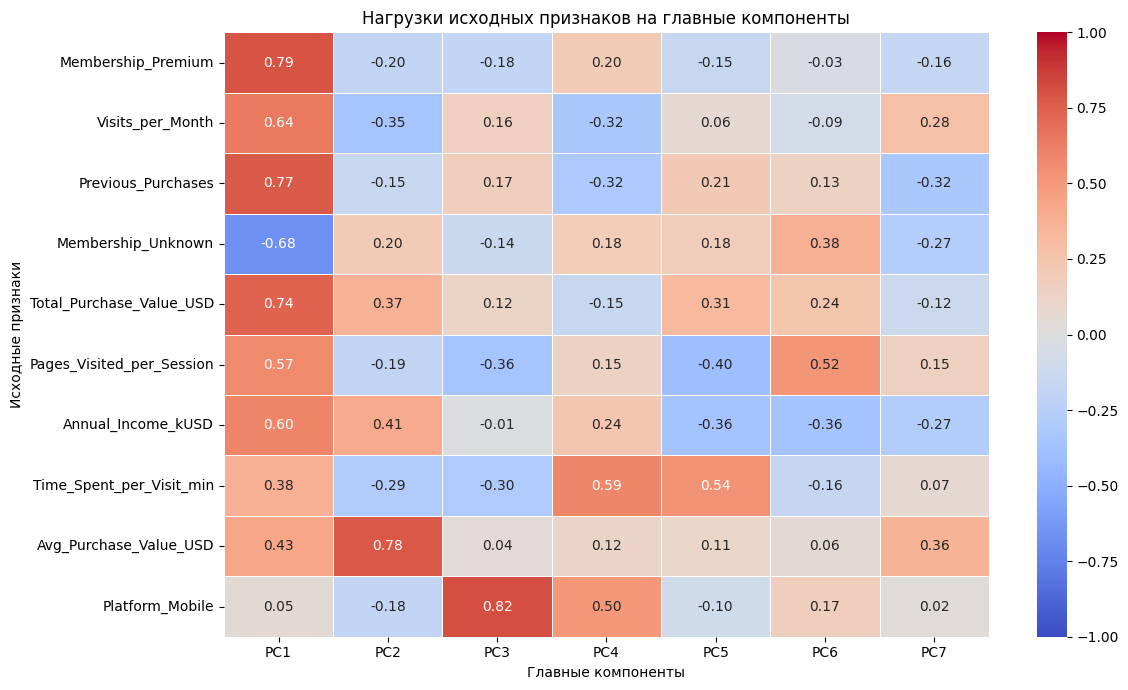

In [ ]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    loadings_df,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Нагрузки исходных признаков на главные компоненты')
plt.xlabel('Главные компоненты')
plt.ylabel('Исходные признаки')
plt.tight_layout()
plt.show()

### PCA biplot

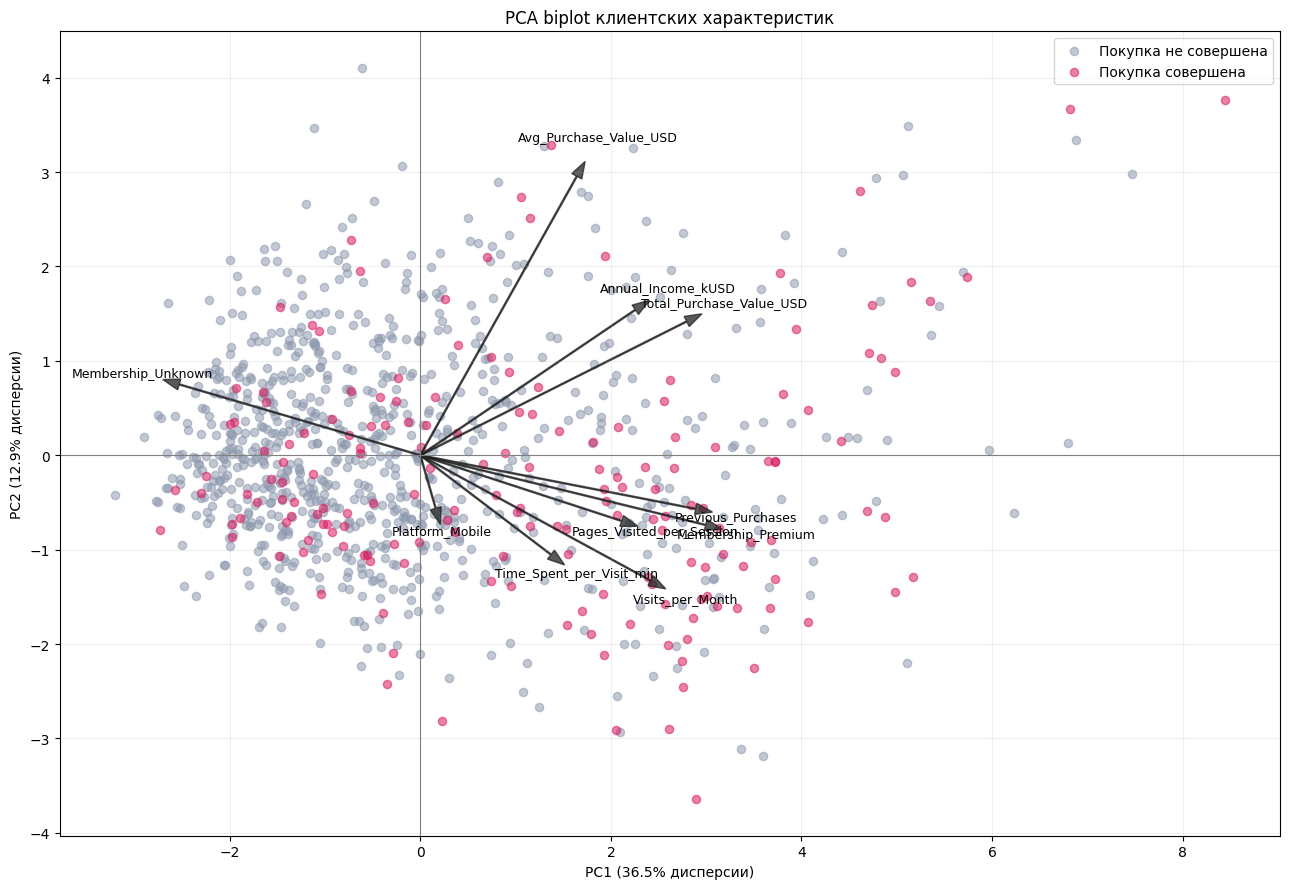

In [ ]:
plt.figure(figsize=(13, 9))

colors = {
    0: '#8E9AAF',
    1: '#D81B60'
}

labels = {
    0: 'Покупка не совершена',
    1: 'Покупка совершена'
}

# Наблюдения в пространстве PC1 и PC2
for target_value in [0, 1]:
    mask = target.to_numpy() == target_value

    plt.scatter(
        X_pca_df.loc[mask, 'PC1'],
        X_pca_df.loc[mask, 'PC2'],
        c=colors[target_value],
        label=labels[target_value],
        alpha=0.55,
        s=35
    )

# Масштаб стрелок для удобного отображения
arrow_scale = 4

for feature in X_final.columns:
    x_loading = loadings_df.loc[feature, 'PC1']
    y_loading = loadings_df.loc[feature, 'PC2']

    plt.arrow(
        0,
        0,
        x_loading * arrow_scale,
        y_loading * arrow_scale,
        color='#222222',
        alpha=0.75,
        width=0.012,
        head_width=0.12,
        length_includes_head=True
    )

    plt.text(
        x_loading * arrow_scale * 1.08,
        y_loading * arrow_scale * 1.08,
        feature,
        fontsize=9,
        ha='center',
        va='center'
    )

plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)

plt.xlabel(
    f'PC1 ({pca_final.explained_variance_ratio_[0] * 100:.1f}% дисперсии)'
)

plt.ylabel(
    f'PC2 ({pca_final.explained_variance_ratio_[1] * 100:.1f}% дисперсии)'
)

plt.title('PCA biplot клиентских характеристик')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Вывод по PCA

Первая главная компонента в основном отражает активность
и покупательскую ценность клиента.

На неё заметно влияют:
- тип подписки;
- количество предыдущих покупок;
- общая сумма покупок;
- частота посещений сайта.

Вторая компонента сильнее связана со средним чеком
и соотношением между денежной ценностью клиента и его активностью.

PCA позволяет сократить исходные 10 признаков до 7 компонент
и сохранить около 89,7% информации.

## 5. t-SNE

t-SNE используется для двумерной визуализации локальной структуры данных.

Для оценки устойчивости результата сравниваются значения perplexity:

- 10;
- 30;
- 50;
- 100.

Целевая переменная `Made_Purchase_Last_Month` используется только для окраски точек
и не входит в признаки, на которых строится t-SNE.

In [ ]:
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score

perplexity_values = [10, 30, 50, 100]

tsne_results = {}
tsne_metrics = []

target_array = target.to_numpy()

for perplexity in perplexity_values:
    tsne_model = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init='pca',
        learning_rate='auto',
        max_iter=1000
    )

    embedding = tsne_model.fit_transform(X_final)

    tsne_results[perplexity] = embedding

    tsne_metrics.append({
        'Perplexity': perplexity,
        'Trustworthiness': trustworthiness(
            X_final,
            embedding,
            n_neighbors=10
        ),
        'Silhouette по целевой переменной': silhouette_score(
            embedding,
            target_array
        ),
        'KL divergence': tsne_model.kl_divergence_
    })

tsne_metrics_df = pd.DataFrame(tsne_metrics)

display(
    tsne_metrics_df.style.format({
        'Trustworthiness': '{:.4f}',
        'Silhouette по целевой переменной': '{:.4f}',
        'KL divergence': '{:.4f}'
    })
)

,Perplexity,Trustworthiness,Silhouette по целевой переменной,KL divergence
0,10,0.9819,0.0551,0.9521
1,30,0.9838,0.0686,0.8417
2,50,0.9832,0.0770,0.7465
3,100,0.9776,0.0873,0.6185


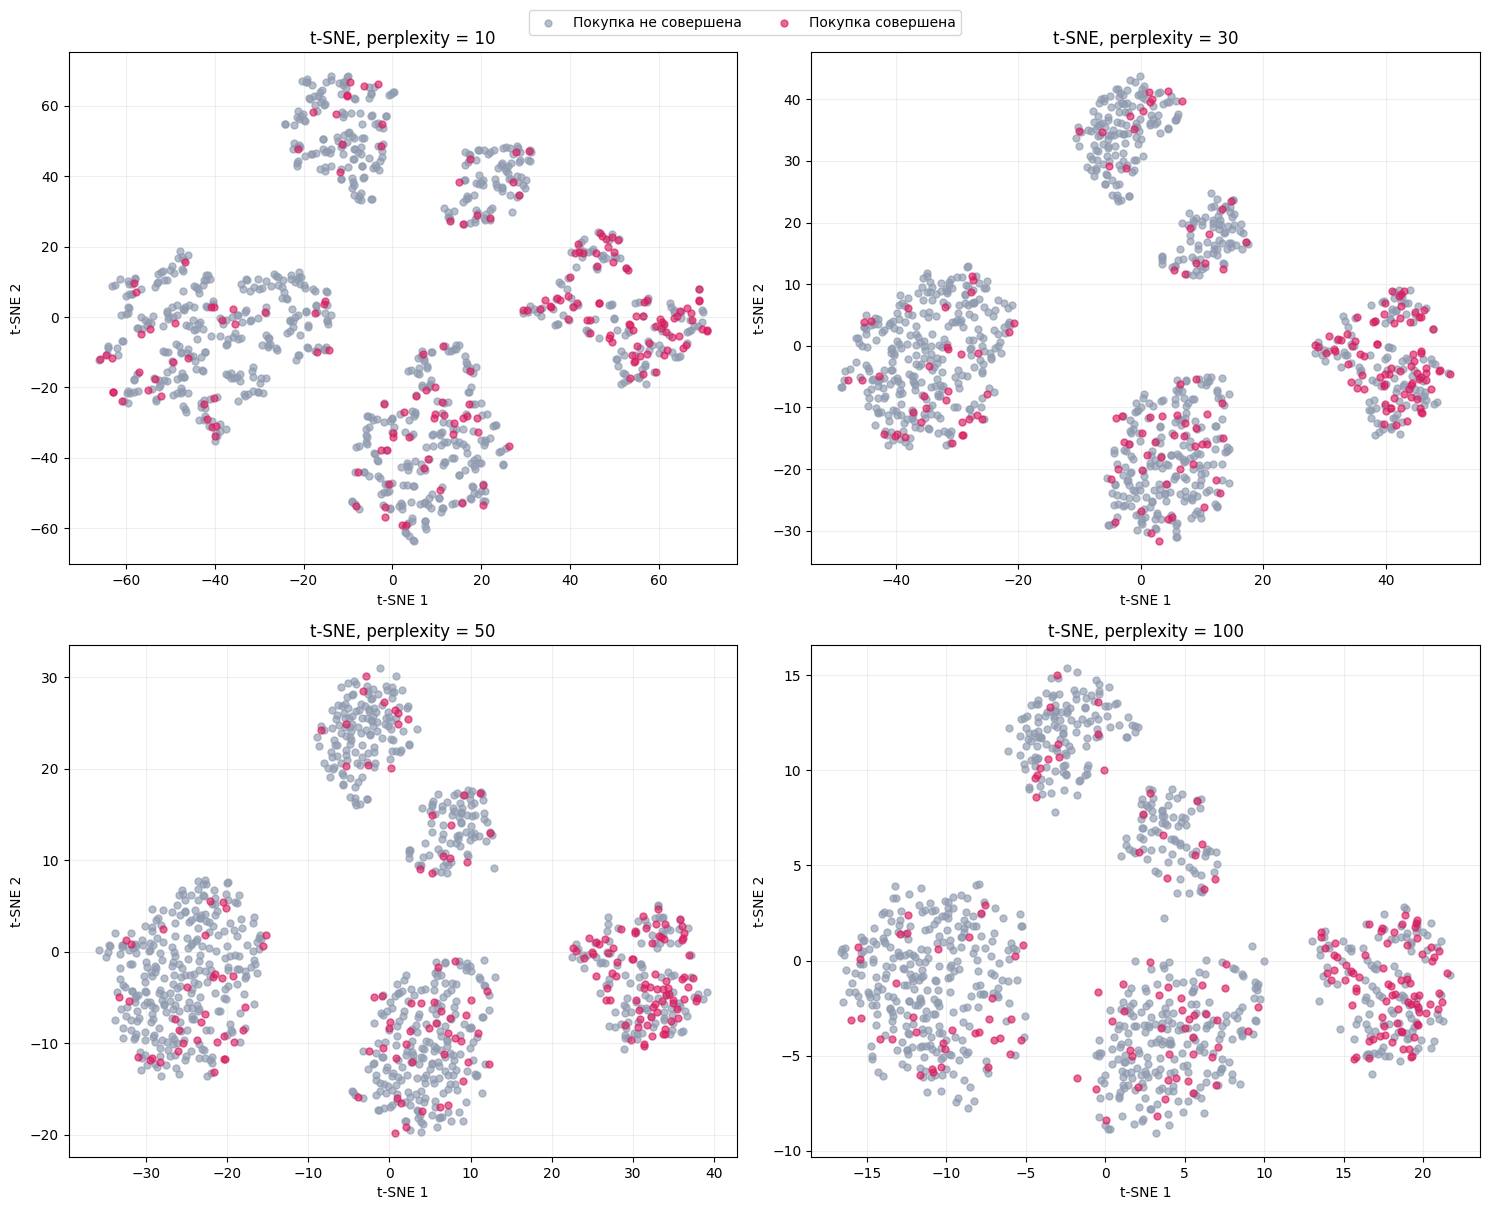

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 12)
)

axes = axes.ravel()

colors = {
    0: '#8E9AAF',
    1: '#D81B60'
}

labels = {
    0: 'Покупка не совершена',
    1: 'Покупка совершена'
}

for axis, perplexity in zip(axes, perplexity_values):
    embedding = tsne_results[perplexity]

    for target_value in [0, 1]:
        mask = target_array == target_value

        axis.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            c=colors[target_value],
            label=labels[target_value],
            s=25,
            alpha=0.65
        )

    axis.set_title(
        f't-SNE, perplexity = {perplexity}'
    )

    axis.set_xlabel('t-SNE 1')
    axis.set_ylabel('t-SNE 2')
    axis.grid(alpha=0.2)

# Общая легенда
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 1.01)
)

plt.tight_layout()
plt.show()

### Вывод по t-SNE

При `perplexity = 10` структура получается слишком раздробленной
и содержит много небольших локальных групп.

При `perplexity = 30` группы становятся более компактными,
при этом локальная структура сохраняется хорошо.

Этот вариант показал наибольшее значение trustworthiness —
примерно **0,984**.

При `perplexity = 50` структура остаётся похожей,
что говорит об относительной устойчивости результата.

При `perplexity = 100` изображение становится более сглаженным,
но часть локальных деталей теряется.

## 6. Бизнес-интерпретация

После анализа структуры данных дополнительно сравниваю характеристики клиентов,
совершивших и не совершивших покупку.

Цель этого блока — связать результаты снижения размерности
с понятными поведенческими и продуктовыми характеристиками клиентов.

In [ ]:
business_data = df.copy()

business_data['Membership'] = (
    business_data['Membership'].fillna('Unknown')
)

business_data['Had_Previous_Purchases'] = (
    business_data['Previous_Purchases'] > 0
)

business_data['Visits_Group'] = pd.cut(
    business_data['Visits_per_Month'],
    bins=[-1, 3, 6, float('inf')],
    labels=[
        'Не более 3 посещений',
        'От 4 до 6 посещений',
        'Более 6 посещений'
    ]
)

print('Общая доля совершивших покупку:')
print(
    business_data['Made_Purchase_Last_Month'].mean().round(3)
)

print('\nДоля покупок по типу подписки:')
display(
    business_data.groupby('Membership')
    ['Made_Purchase_Last_Month']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

print('\nДоля покупок в зависимости от предыдущих покупок:')
display(
    business_data.groupby('Had_Previous_Purchases')
    ['Made_Purchase_Last_Month']
    .agg(['count', 'mean'])
)

print('\nДоля покупок по частоте посещений:')
display(
    business_data.groupby(
        'Visits_Group',
        observed=True
    )['Made_Purchase_Last_Month']
    .agg(['count', 'mean'])
)

Общая доля совершивших покупку:
0.173

Доля покупок по типу подписки:


,count,mean
Membership,,
Premium,192,0.406250
Basic,341,0.140762
Unknown,467,0.100642



Доля покупок в зависимости от предыдущих покупок:


,count,mean
Had_Previous_Purchases,,
False,303,0.09571
True,697,0.20660



Доля покупок по частоте посещений:


,count,mean
Visits_Group,,
Не более 3 посещений,314,0.066879
От 4 до 6 посещений,443,0.148984
Более 6 посещений,243,0.353909


## 7. Итоги

В проекте были подготовлены данные о клиентах интернет-магазина,
проведён отбор признаков и применены два метода снижения размерности:
PCA и t-SNE.

Основные результаты:

- после отбора осталось 10 признаков;
- KMO итогового набора составил около 0,749;
- 7 компонент PCA сохраняют около 89,7% исходной дисперсии;
- наиболее информативной t-SNE-визуализацией оказался вариант
  с `perplexity = 30`;
- trustworthiness для него составил около 0,984.

Покупатели и непокупатели не образуют полностью отдельных групп,
однако Premium-подписка, высокая активность и история предыдущих покупок
чаще встречаются у клиентов, совершивших покупку.

Полученные результаты можно использовать как основу для дальнейшей
сегментации клиентов и разработки персонализированных продуктовых гипотез.

Выявленные связи являются описательными и не доказывают причинность.